<div style="text-align: center; font-style: italic; font-size: 18px">Water Resources Management</div>
<div></div>
<div style="text-align: center">Supplementary Information of</div>
<div style="text-align: center; font-weight: bold; font-size: 24px">Data-Driven Leak Localization Modeling for Optimal Sensor Placement</div>

---

Maria Gloria Di Chiano<sup>1*</sup>, Dennis Zanutto<sup>2,3</sup>, Gianfranco Becciu<sup>1</sup>, Dragan Savić<sup>3,4</sup>

<sup>1</sup>D.I.C.A. Politecnico di Milano, 20133 Milano, Italy

<sup>2</sup>D.E.I.B, Politecnico di Milano, 20133, Milano, Italy

<sup>3</sup>KWR Water Research Institute, Nieuwegein, 3430 BB, the Netherlands

<sup>4</sup>Centre for Water Systems, University of Exeter, Exeter, EX4 4QF, United Kingdom


## Content of this File

- Text S1.1
- Text S1.2

## Introduction
This notebook tests whether the settings proposed by Boatwright et al. for their leak signature matrix (LSM) reconstruction method are optimal, or whether specific choices can change leak localization (LL) performances of this method.

In [ ]:
# Imports
from wdn_osp_ll.sensor_placement_optimization import load_or_compute
from wdn_osp_ll.visualization import (
    plot_pareto_front_nsensors_msa,
    plot_hypervolume_bar,
    plot_hypervolume_trajectory,
)

## Text S1

### S1.1 — Integrated vs. sequential optimization of leak localization parameters

The goal of this comparison is to test whether optimizing the leak localization (LL) algorithm's parameters jointly with the sensor configuration — within the integrated optimal sensor placement problem — is beneficial, compared to optimizing them separately.

As the number of parameters grows, testing all combinations becomes computationally expensive: the number of configurations grows exponentially, and compute time accumulates accordingly. With this sequential approach, we can only identify the best-performing configuration among those tested, not necessarily the true optimum.

Running an integrated optimization could in principle find the optimal parametrization for each sensor configuration. However, it also risks confusing the optimization algorithm, leading to non-convergence or convergence to a local minimum rather than the global optimum.

In [ ]:
suggested_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": 14.5,
            "signature_matrix": "chi_squared",
            "scale_nodes_by_scenario_mean": True,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "boatwright",
                    "args": {
                        "metric": "length",
                        "directed": False,
                        "exponent": None,
                    },
                },
                "search_area_definition_method": {
                    "name": "relative_threshold",
                    "args": {
                        "threshold": None,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

suggested_res = load_or_compute(config=suggested_cfg)

Starting optimisation...
[2026-11-06 12:07:00] generation      0 | best hypervolume: 173.741935 | median: 116.983871
[2026-11-06 12:07:02] generation     10 | best hypervolume: 320.451613 | median: 309.758065
[2026-11-06 12:07:03] generation     20 | best hypervolume: 338.645161 | median: 330.322581
[2026-11-06 12:07:03] generation     30 | best hypervolume: 343.225806 | median: 334.112903
[2026-11-06 12:07:04] generation     40 | best hypervolume: 344.161290 | median: 335.258065
[2026-11-06 12:07:04] generation     50 | best hypervolume: 345.387097 | median: 336.919355
[2026-11-06 12:07:04] generation     60 | best hypervolume: 345.516129 | median: 338.306452
[2026-11-06 12:07:05] generation     70 | best hypervolume: 345.516129 | median: 338.516129
[2026-11-06 12:07:05] generation     80 | best hypervolume: 345.612903 | median: 340.241935
[2026-11-06 12:07:06] generation     90 | best hypervolume: 346.193548 | median: 340.370968
[2026-11-06 12:07:06] generation    100 | best hypervol

In [ ]:
fix_exponent_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": 14.5,
            "signature_matrix": "chi_squared",
            "scale_nodes_by_scenario_mean": True,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "boatwright",
                    "args": {
                        "metric": "length",
                        "directed": False,
                        "exponent": 2,
                    },
                },
                "search_area_definition_method": {
                    "name": "relative_threshold",
                    "args": {
                        "threshold": None,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

fix_exponent_res = load_or_compute(config=fix_exponent_cfg)

Starting optimisation...
[2026-11-06 12:07:06] generation      0 | best hypervolume: 162.387097 | median: 134.258065
[2026-11-06 12:07:07] generation     10 | best hypervolume: 306.322581 | median: 297.370968
[2026-11-06 12:07:07] generation     20 | best hypervolume: 320.000000 | median: 317.193548
[2026-11-06 12:07:08] generation     30 | best hypervolume: 325.032258 | median: 320.709677
[2026-11-06 12:07:08] generation     40 | best hypervolume: 325.612903 | median: 322.516129
[2026-11-06 12:07:08] generation     50 | best hypervolume: 326.645161 | median: 323.419355
[2026-11-06 12:07:09] generation     60 | best hypervolume: 326.903226 | median: 323.887097
[2026-11-06 12:07:09] generation     70 | best hypervolume: 327.548387 | median: 324.870968
[2026-11-06 12:07:09] generation     80 | best hypervolume: 328.258065 | median: 326.161290
[2026-11-06 12:07:10] generation     90 | best hypervolume: 329.548387 | median: 326.564516
[2026-11-06 12:07:10] generation    100 | best hypervol

In [ ]:
fix_threshold_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": 14.5,
            "signature_matrix": "chi_squared",
            "scale_nodes_by_scenario_mean": True,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "boatwright",
                    "args": {
                        "metric": "length",
                        "directed": False,
                        "exponent": None,
                    },
                },
                "search_area_definition_method": {
                    "name": "relative_threshold",
                    "args": {
                        "threshold": 0.7,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

fix_threshold_res = load_or_compute(config=fix_threshold_cfg)

Starting optimisation...
[2026-11-06 12:07:11] generation      0 | best hypervolume: 183.064516 | median: 145.661290
[2026-11-06 12:07:11] generation     10 | best hypervolume: 320.516129 | median: 313.854839
[2026-11-06 12:07:11] generation     20 | best hypervolume: 326.451613 | median: 322.451613
[2026-11-06 12:07:12] generation     30 | best hypervolume: 329.225806 | median: 325.693548
[2026-11-06 12:07:12] generation     40 | best hypervolume: 329.645161 | median: 326.870968
[2026-11-06 12:07:12] generation     50 | best hypervolume: 331.064516 | median: 328.983871
[2026-11-06 12:07:13] generation     60 | best hypervolume: 331.225806 | median: 329.225806
[2026-11-06 12:07:13] generation     70 | best hypervolume: 331.225806 | median: 329.258065
[2026-11-06 12:07:14] generation     80 | best hypervolume: 331.258065 | median: 329.419355
[2026-11-06 12:07:14] generation     90 | best hypervolume: 331.258065 | median: 329.887097
[2026-11-06 12:07:14] generation    100 | best hypervol

In [ ]:
fix_exponent_threshold_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": 14.5,
            "signature_matrix": "chi_squared",
            "scale_nodes_by_scenario_mean": True,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "boatwright",
                    "args": {
                        "metric": "length",
                        "directed": False,
                        "exponent": 2,
                    },
                },
                "search_area_definition_method": {
                    "name": "relative_threshold",
                    "args": {
                        "threshold": 0.7,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

fix_exponent_threshold_res = load_or_compute(config=fix_exponent_threshold_cfg)

Starting optimisation...
[2026-11-06 12:07:15] generation      0 | best hypervolume: 203.129032 | median: 151.177419
[2026-11-06 12:07:15] generation     10 | best hypervolume: 313.161290 | median: 299.387097
[2026-11-06 12:07:15] generation     20 | best hypervolume: 322.032258 | median: 316.016129
[2026-11-06 12:07:16] generation     30 | best hypervolume: 325.741935 | median: 317.935484
[2026-11-06 12:07:16] generation     40 | best hypervolume: 325.935484 | median: 319.903226
[2026-11-06 12:07:17] generation     50 | best hypervolume: 326.516129 | median: 322.016129
[2026-11-06 12:07:17] generation     60 | best hypervolume: 327.064516 | median: 322.403226
[2026-11-06 12:07:17] generation     70 | best hypervolume: 327.064516 | median: 322.887097
[2026-11-06 12:07:18] generation     80 | best hypervolume: 327.064516 | median: 323.580645
[2026-11-06 12:07:18] generation     90 | best hypervolume: 327.580645 | median: 323.903226
[2026-11-06 12:07:19] generation    100 | best hypervol

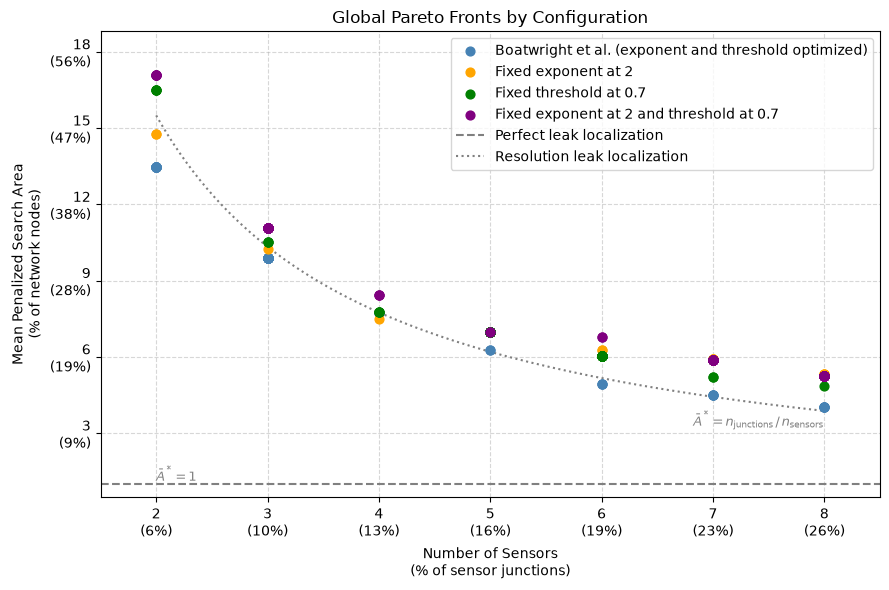

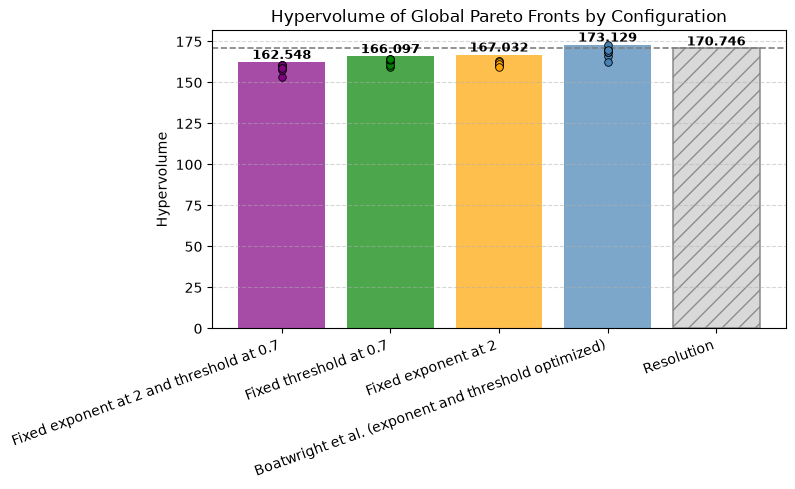

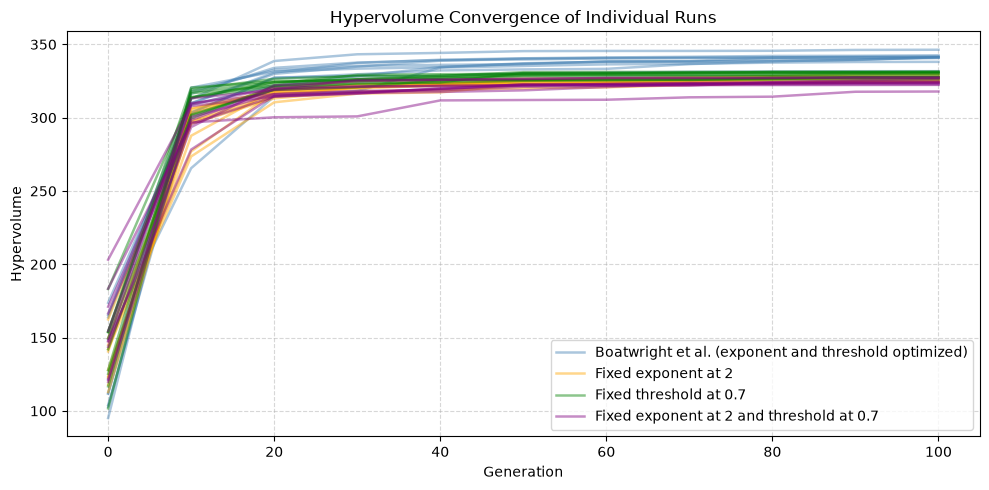

In [ ]:
results = [suggested_res, fix_exponent_res, fix_threshold_res, fix_exponent_threshold_res]
labels = ["Boatwright et al. (exponent and threshold optimized)", "Fixed exponent at 2", "Fixed threshold at 0.7", "Fixed exponent at 2 and threshold at 0.7"]
colors = ["steelblue", "orange", "green", "purple"]

fig, ax = plot_pareto_front_nsensors_msa(results, labels, colors)
fig, ax = plot_hypervolume_bar(results, labels, colors)
fig, ax = plot_hypervolume_trajectory(results, labels, colors)

**Results.** Integrated optimization consistently outperforms the sequential approach, particularly with respect to the relative threshold defining the search area. This is intuitive: as the number of sensors increases and configuration performance improves, the threshold can be progressively tightened, effectively narrowing the set of candidate nodes selected by the search.

### S1.2 — Impact of Scenario-based Scaling and Choice of the Leak Signature Matrix

The goal of this comparison is to test whether using the chi-squared matrix with scaling by each node's mean response across leak scenarios as LSM is the correct choice or alternative formulations perform better.
We compare against the same matrix, but not scaled, and when using the sensitivity matrix, both in the scaled and non-scaled variants.


In [ ]:
no_scaling_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": 14.5,
            "signature_matrix": "chi_squared",
            "scale_nodes_by_scenario_mean": False,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "boatwright",
                    "args": {
                        "metric": "length",
                        "directed": False,
                        "exponent": None,
                    },
                },
                "search_area_definition_method": {
                    "name": "relative_threshold",
                    "args": {
                        "threshold": None,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

no_scaling_res = load_or_compute(config=no_scaling_cfg)

Starting optimisation...
[2026-11-06 12:07:19] generation      0 | best hypervolume: 133.967742 | median: 118.096774
[2026-11-06 12:07:20] generation     10 | best hypervolume: 281.548387 | median: 268.854839
[2026-11-06 12:07:20] generation     20 | best hypervolume: 299.322581 | median: 288.548387
[2026-11-06 12:07:20] generation     30 | best hypervolume: 303.838710 | median: 293.048387
[2026-11-06 12:07:21] generation     40 | best hypervolume: 306.225806 | median: 296.080645
[2026-11-06 12:07:21] generation     50 | best hypervolume: 307.645161 | median: 297.370968
[2026-11-06 12:07:22] generation     60 | best hypervolume: 310.096774 | median: 300.016129
[2026-11-06 12:07:22] generation     70 | best hypervolume: 310.096774 | median: 300.548387
[2026-11-06 12:07:23] generation     80 | best hypervolume: 310.419355 | median: 301.516129
[2026-11-06 12:07:23] generation     90 | best hypervolume: 310.709677 | median: 302.032258
[2026-11-06 12:07:23] generation    100 | best hypervol

In [ ]:
sensmat_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": 14.5,
            "signature_matrix": "sensitivity",
            "scale_nodes_by_scenario_mean": False,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "boatwright",
                    "args": {
                        "metric": "length",
                        "directed": False,
                        "exponent": None,
                    },
                },
                "search_area_definition_method": {
                    "name": "relative_threshold",
                    "args": {
                        "threshold": None,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

sensmat_res = load_or_compute(config=sensmat_cfg)

Starting optimisation...
[2026-11-06 12:07:24] generation      0 | best hypervolume: 142.193548 | median: 108.967742
[2026-11-06 12:07:24] generation     10 | best hypervolume: 295.967742 | median: 280.564516
[2026-11-06 12:07:24] generation     20 | best hypervolume: 304.258065 | median: 297.838710
[2026-11-06 12:07:25] generation     30 | best hypervolume: 307.387097 | median: 300.370968
[2026-11-06 12:07:25] generation     40 | best hypervolume: 311.612903 | median: 302.145161
[2026-11-06 12:07:26] generation     50 | best hypervolume: 313.354839 | median: 303.919355
[2026-11-06 12:07:26] generation     60 | best hypervolume: 313.451613 | median: 304.741935
[2026-11-06 12:07:26] generation     70 | best hypervolume: 314.709677 | median: 305.096774
[2026-11-06 12:07:27] generation     80 | best hypervolume: 314.838710 | median: 305.887097
[2026-11-06 12:07:27] generation     90 | best hypervolume: 314.935484 | median: 306.225806
[2026-11-06 12:07:28] generation    100 | best hypervol

In [ ]:
sensmat_scaled_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": 14.5,
            "signature_matrix": "sensitivity",
            "scale_nodes_by_scenario_mean": True,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "boatwright",
                    "args": {
                        "metric": "length",
                        "directed": False,
                        "exponent": None,
                    },
                },
                "search_area_definition_method": {
                    "name": "relative_threshold",
                    "args": {
                        "threshold": None,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

sensmat_scaled_res = load_or_compute(config=sensmat_scaled_cfg)

Starting optimisation...
[2026-11-06 12:07:28] generation      0 | best hypervolume: 146.419355 | median: 116.838710
[2026-11-06 12:07:28] generation     10 | best hypervolume: 322.483871 | median: 309.225806
[2026-11-06 12:07:29] generation     20 | best hypervolume: 334.000000 | median: 331.258065
[2026-11-06 12:07:29] generation     30 | best hypervolume: 338.709677 | median: 334.725806
[2026-11-06 12:07:29] generation     40 | best hypervolume: 339.709677 | median: 336.451613
[2026-11-06 12:07:30] generation     50 | best hypervolume: 340.935484 | median: 337.161290
[2026-11-06 12:07:30] generation     60 | best hypervolume: 341.354839 | median: 337.774194
[2026-11-06 12:07:31] generation     70 | best hypervolume: 341.387097 | median: 338.661290
[2026-11-06 12:07:31] generation     80 | best hypervolume: 341.516129 | median: 339.322581
[2026-11-06 12:07:32] generation     90 | best hypervolume: 341.516129 | median: 339.661290
[2026-11-06 12:07:32] generation    100 | best hypervol

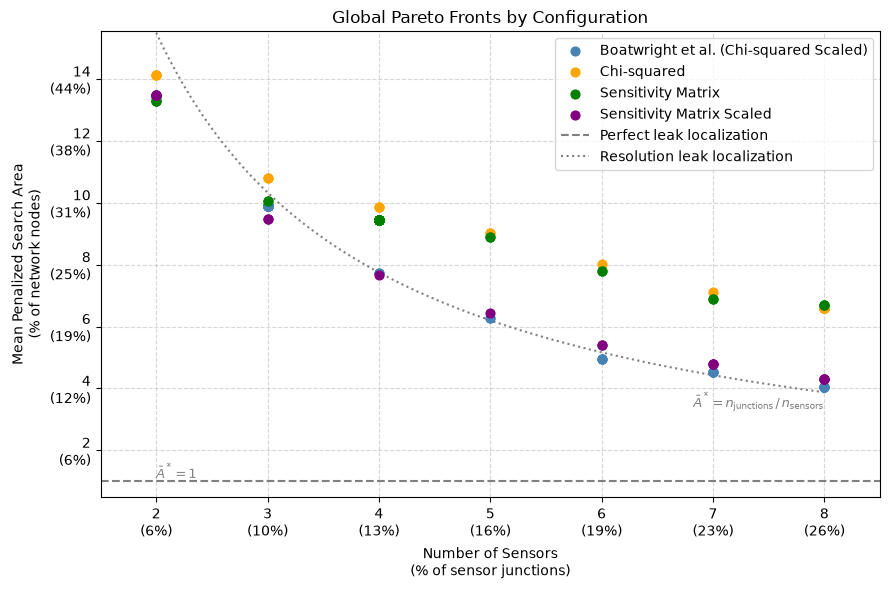

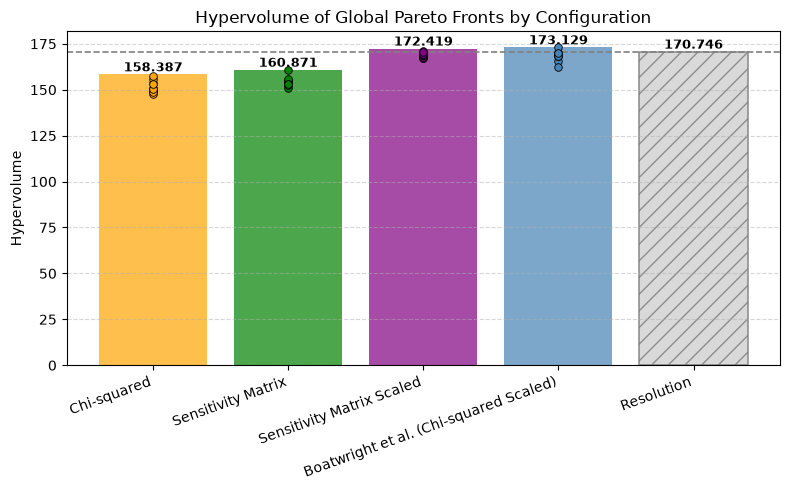

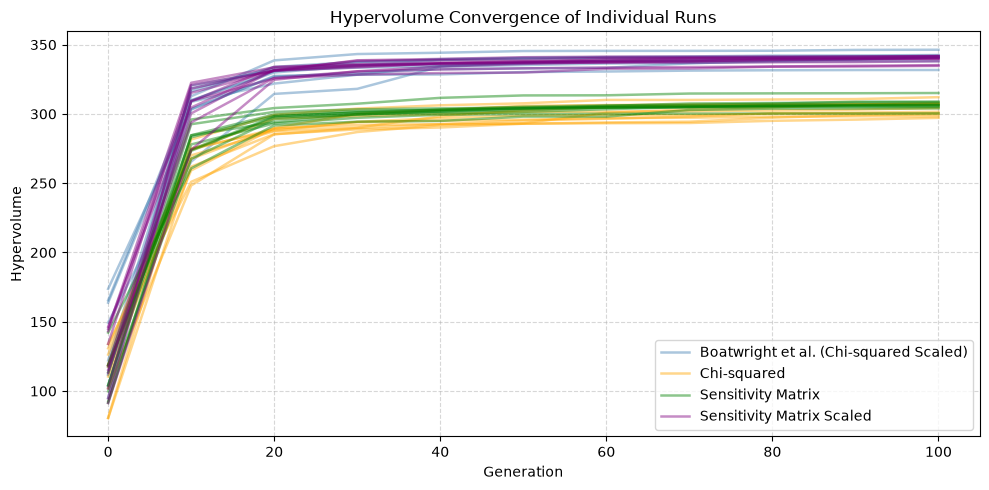

In [ ]:
results = [suggested_res, no_scaling_res, sensmat_res, sensmat_scaled_res]
labels = ["Boatwright et al. (Chi-squared Scaled)", "Chi-squared", "Sensitivity Matrix", "Sensitivity Matrix Scaled"]
colors = ["steelblue", "orange", "green", "purple"]

fig, ax = plot_pareto_front_nsensors_msa(results, labels, colors)
fig, ax = plot_hypervolume_bar(results, labels, colors)
fig, ax = plot_hypervolume_trajectory(results, labels, colors)

**Results.** The scaled versions of the Sensitivity Matrix and Chi-squared Matrix perform significantly better than their non-scaled variants, while the difference between the two types of matrix is much smaller.
If confermed on the other benchmark networks, this would indicate that the scaling step is necessary and brings the most value to the methodology.
However, this can be done only if a calibrated hydraulic models is available before the Optimal Sensor Placement problem is solved.